In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import tifffile
from PIL import Image
import numpy as np
from scipy.optimize import curve_fit
from scipy.integrate import cumulative_trapezoid
from scipy.signal import savgol_filter
import pandas as pd
import matplotlib.transforms as mtransforms
from statsmodels.nonparametric.smoothers_lowess import lowess
import cmcrameri.cm as cm

import analysis_functions as afn

In [2]:
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-nr.tif') as img:
    streak_pre_nr = np.array(img)
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-r.tif') as img:
    streak_pre_r = np.array(img)   
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak.tif') as img:
    streak = np.array(img)   

calib = pd.read_csv('streak_calib.csv')

In [3]:
px_to_mm = calib['value'].values[0]
px_to_ns = calib['value'].values[1]
print(px_to_mm)

cmax = np.percentile(streak, 99)

0.0111469960824503


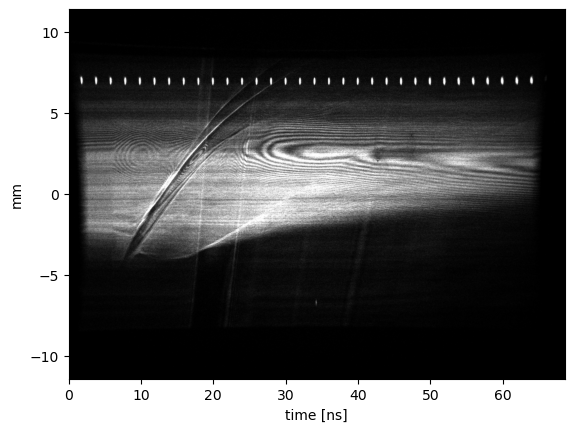

In [4]:
extent_x = streak.shape[1] * px_to_ns
extent_y = streak.shape[0] * px_to_mm
ext=[0, extent_x, -extent_y/2, extent_y/2]

plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.savefig('streak_images/streak.jpg', bbox_inches = 'tight')

In [5]:
times_bkgd = np.linspace(3, 5, 51)
times_bkgd = np.array(times_bkgd)
pos_bkgd = []
lineouts_bkgd = []
for t in times_bkgd:
    y, lo = afn.plot_vlineout_streak(t_ns = t, ext = ext, image =streak, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    lineouts_bkgd.append(lo)
    pos_bkgd.append(y)
pos_bkgd = np.array(pos_bkgd)
lineouts_bkgd = np.array(lineouts_bkgd, dtype=object)

mask = (times_bkgd > 4.0) | (times_bkgd < 3.5)
times_bkgd = times_bkgd[mask]
pos_bkgd = pos_bkgd[mask]
lineouts_bkgd = lineouts_bkgd[mask]

In [6]:
background = np.mean(lineouts_bkgd, axis = 0)

In [7]:
times_shock = np.linspace(10, 20, 21)
times_shock = np.array(times_shock)
pos_shock = []
lineouts_shock = []
for t in times_shock:
    y1, lo1 = afn.plot_vlineout_streak(t_ns = t - px_to_ns, ext = ext, image =streak, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    y2, lo2 = afn.plot_vlineout_streak(t_ns = t, ext = ext, image =streak, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    y3, lo3 = afn.plot_vlineout_streak(t_ns = t + px_to_ns, ext = ext, image =streak, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    lineouts_shock.append(np.average([lo1, lo2, lo3], axis = 0))
    pos_shock.append(np.average([y1, y2, y3], axis = 0))
pos_shock = np.array(pos_shock)
lineouts_shock = np.array(lineouts_shock, dtype=object)

lineouts_shock_bkgdsub = (lineouts_shock - background)

(0.0, 25.0)

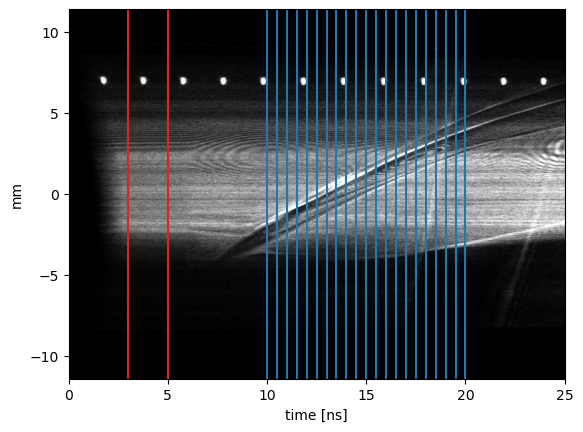

In [8]:
plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

for i in range(len(times_shock)):
    plt.axvline(times_shock[i])

plt.axvline(times_bkgd[0], color = 'tab:red')
plt.axvline(times_bkgd[37], color = 'tab:red')

plt.xlim(0, 25)

# plt.savefig('streak_images/bkgd/lineout_positions_shock', bbox_inches = 'tight')

In [9]:
times_shock_late = np.linspace(16, 25, 19)
times_shock_late = np.array(times_shock_late)
pos_shock_late = []
lineouts_shock_late = []
for t in times_shock_late:
    y1, lo1 = afn.plot_vlineout_streak(t_ns = t - px_to_ns, ext = ext, image =streak, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    y2, lo2 = afn.plot_vlineout_streak(t_ns = t, ext = ext, image =streak, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    y3, lo3 = afn.plot_vlineout_streak(t_ns = t + px_to_ns, ext = ext, image =streak, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    lineouts_shock_late.append(np.average([lo1, lo2, lo3], axis = 0))
    pos_shock_late.append(np.average([y1, y2, y3], axis = 0))
pos_shock_late = np.array(pos_shock_late)
lineouts_shock_late = np.array(lineouts_shock_late, dtype=object)

lineouts_shock_bkgdsub_late = (lineouts_shock_late - background)

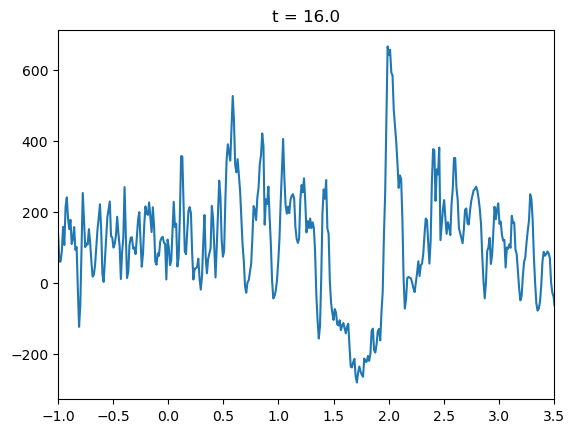

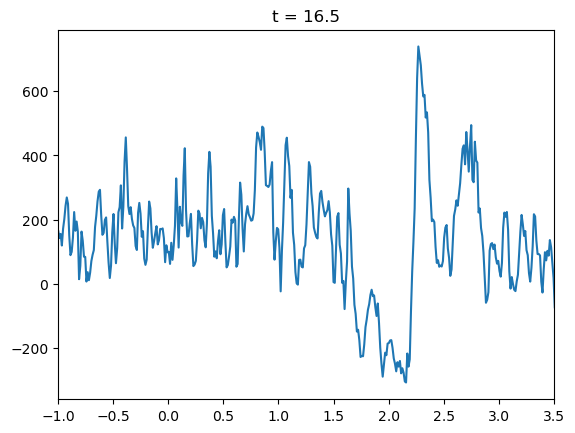

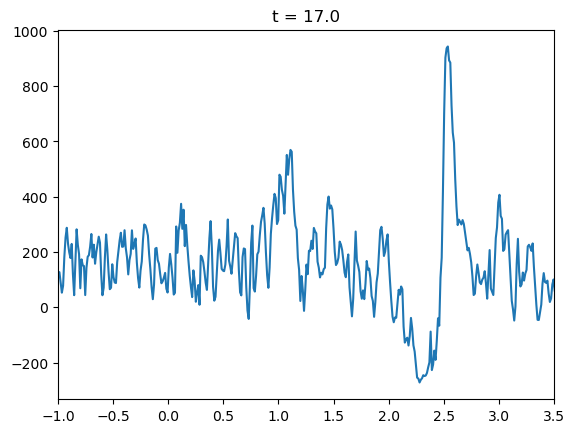

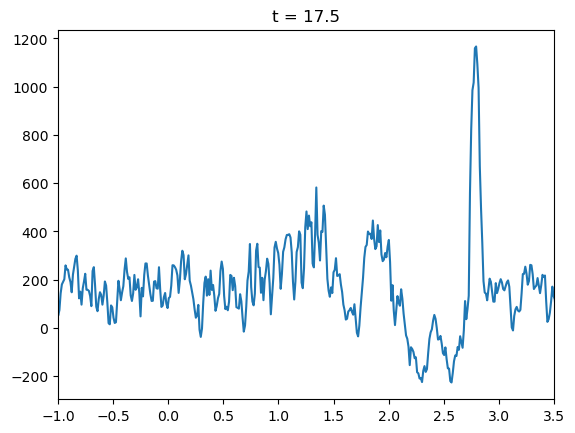

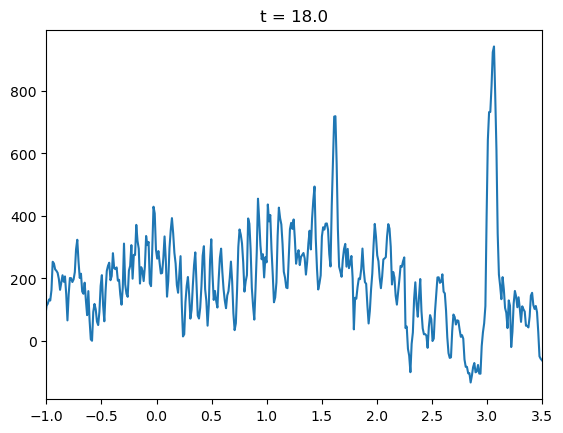

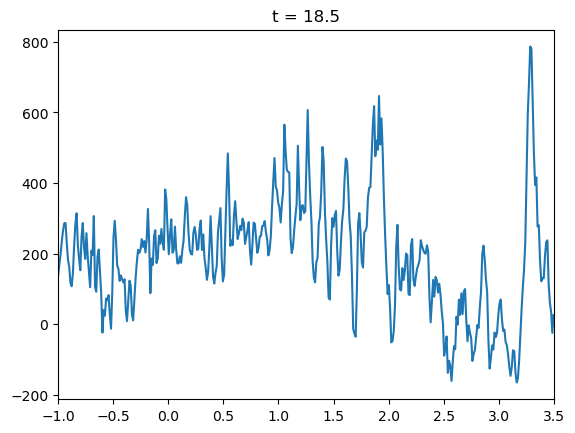

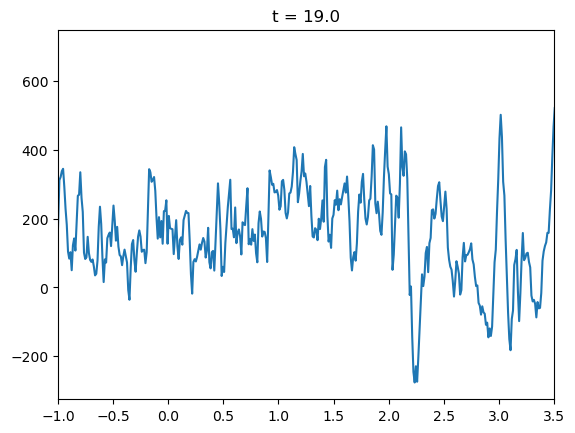

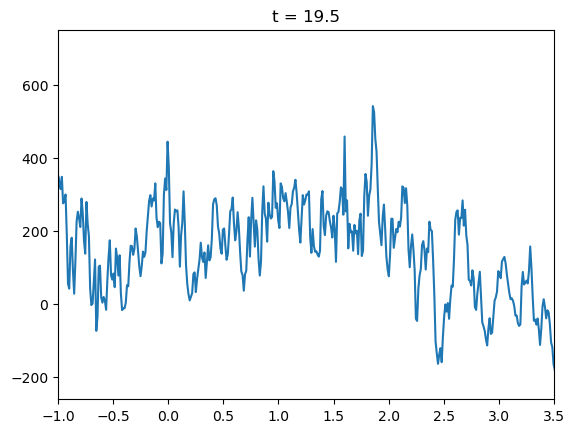

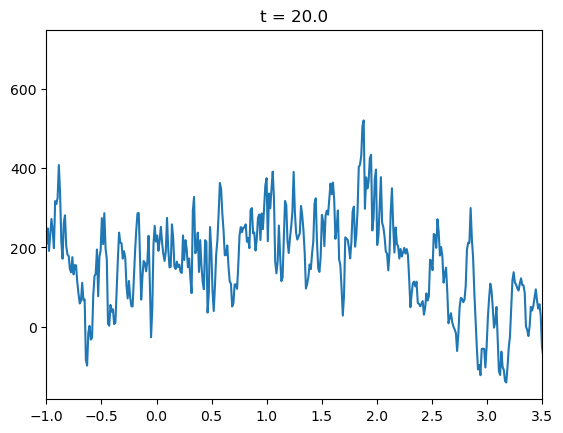

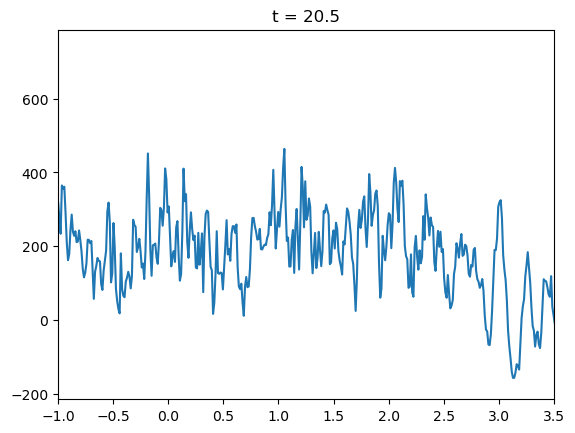

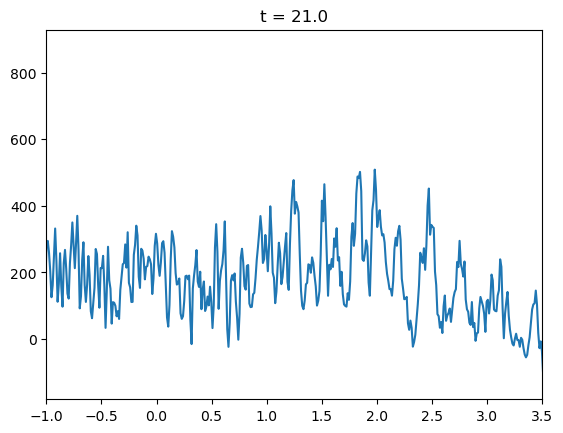

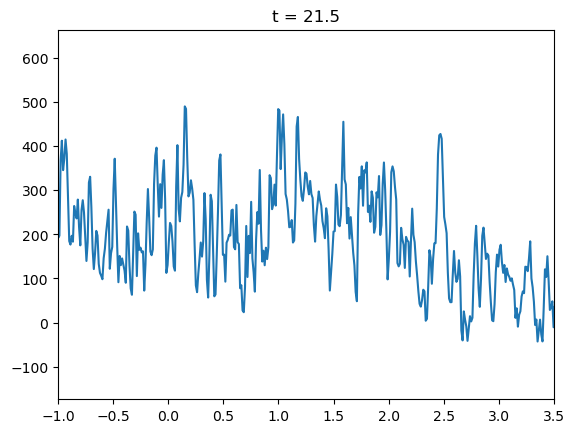

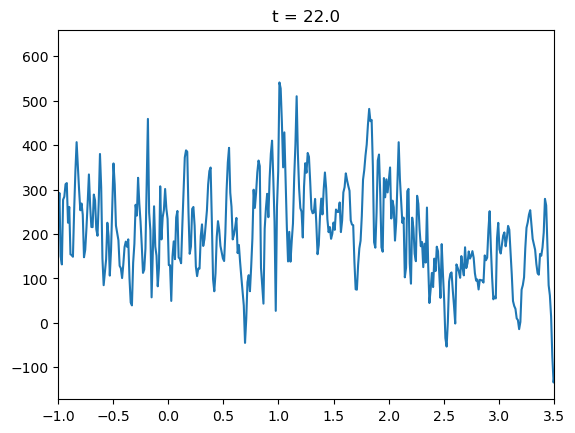

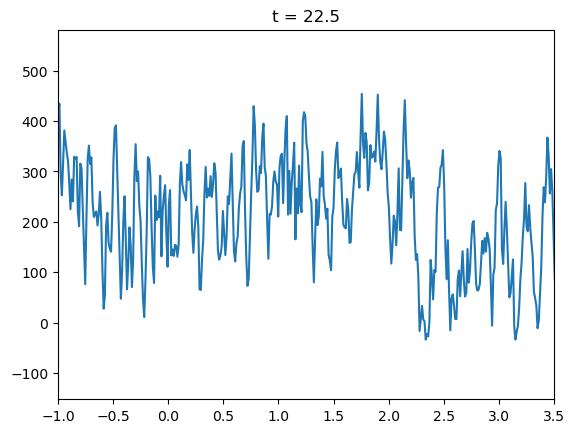

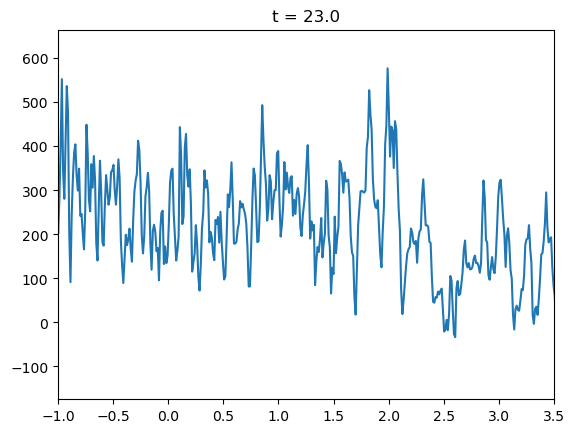

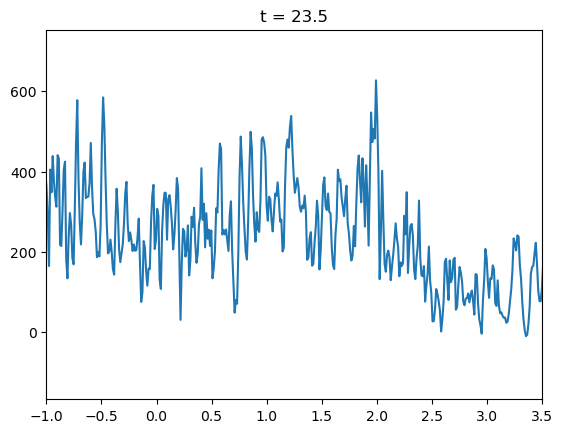

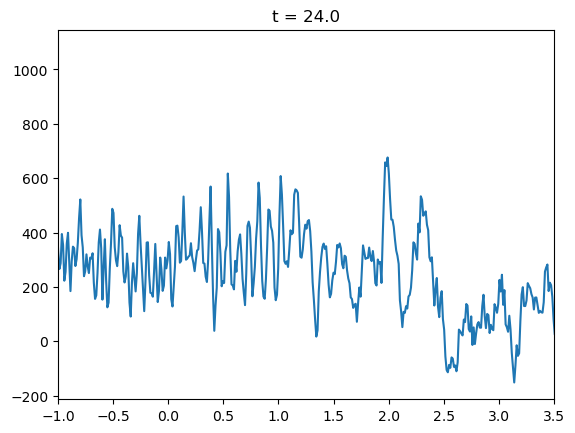

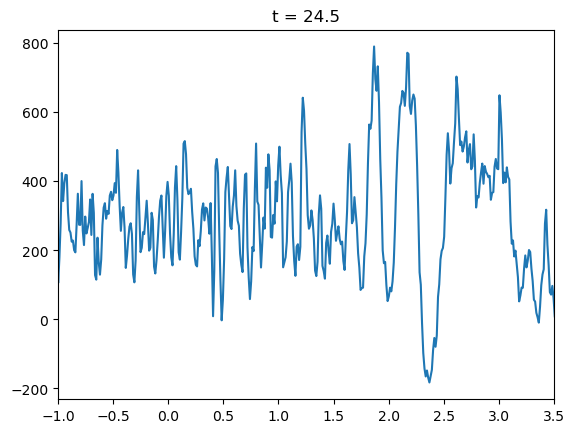

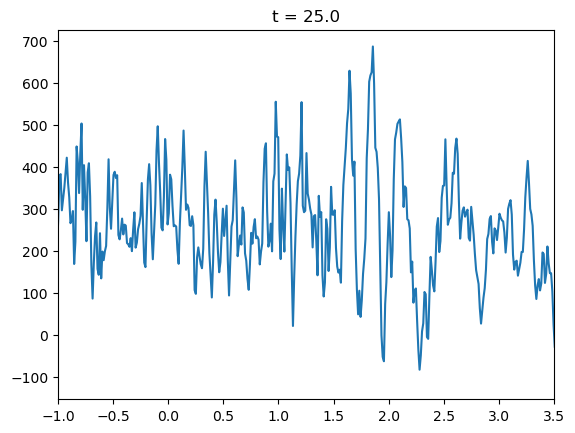

<Figure size 640x480 with 0 Axes>

In [10]:
for i in range(len(pos_shock_late)):
    plt.plot(pos_shock_late[i], lineouts_shock_bkgdsub_late[i])
    plt.title(f't = {times_shock_late[i]}')
    plt.xlim(-1,3.5)
    plt.show()
    plt.clf()

# Model Shocks

In [11]:
def double_gaussian(x, x1, w1, A1, x2, w2, A2):
    peak_neg = A1 * np.exp(-((x - x1) / w1)**2)
    peak_pos = A2 * np.exp(-((x - x2) / w2)**2)
    return peak_neg + peak_pos

In [12]:
wavelength_um = 0.532 # 0.532 microns
m = 1 # magnification = 1
n_c = 1.1e21/(wavelength_um**2)
L = 4.16 # 4160 mm to first lens

dens_corr = (2*m*n_c)/L
print(n_c)
print(dens_corr)

3.8865961897224254e+21
1.8685558604434736e+21


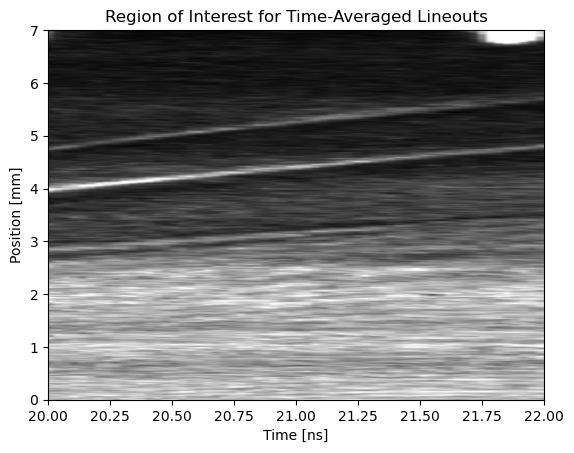

In [15]:
plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('Time [ns]')
plt.ylabel('Position [mm]')

plt.xlim(20, 22)
plt.ylim(0,7)
plt.title('Region of Interest for Time-Averaged Lineouts')
plt.savefig('streak_images/zfs/shock_avg_im_2022', bbox_inches = 'tight')

In [60]:
# average lineouts over 2 ns 
times_r1 = np.linspace(18, 20, 51)
times_r1 = np.array(times_r1)
pos_r1 = []
lineouts_r1 = []
for t in times_r1:
    y, lo = afn.plot_vlineout_streak(t_ns = t, ext = ext, image =streak, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    lineouts_r1.append(lo)
    pos_r1.append(y)
pos_r1 = np.array(pos_r1)
lineouts_r1 = np.array(lineouts_r1, dtype=object)

lineouts_r1 = (lineouts_r1 - background)/background

print(len(times_r1))
# mask = (times_r1 > 4.0) | (times_r1 < 3.5)
# times_r1 = times_r1[mask]
# pos_bkgd = pos_bkgd[mask]
# lineouts_bkgd = lineouts_bkgd[mask]

51


In [61]:
pos_shifted_r1 = []
lineouts_shifted_r1 = []
x_common = np.linspace(-2, 2, 1000)

for i in range(len(times_r1)):
    x_data = np.asarray(pos_r1[i], dtype=float)
    y_data = np.asarray(lineouts_r1[i], dtype=float)
    min,max = 3,6
    if (i == 22 or i == 23 or i == 27):
        min, max = 3.4, 3.7
    mask_piston = (x_data >= min) & (x_data <= max)
    x_fit_p, y_fit_p = x_data[mask_piston],y_data[mask_piston]
    piston_max=(x_fit_p[np.argmax(y_fit_p)])
    # print(f'lineout {i}: t = {times_r1[i]}, piston = {piston_max}')

    x_shifted = x_data - piston_max
    sort_idx = np.argsort(x_shifted)
    x_sorted = x_shifted[sort_idx]
    y_sorted = y_data[sort_idx]

    # Interpolate onto common axis
    y_interp = np.interp(x_common, x_sorted, y_sorted)
    
    pos_shifted_r1.append(x_shifted)
    lineouts_shifted_r1.append(y_interp)

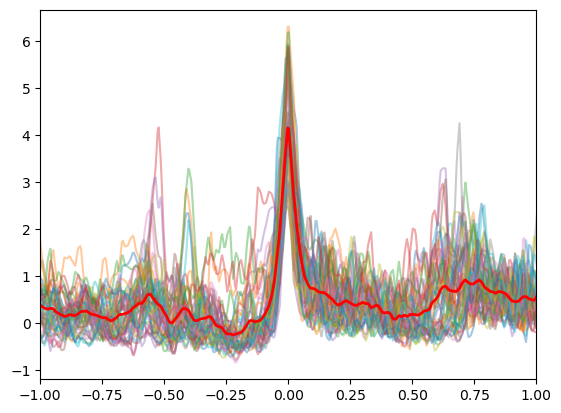

In [62]:
N_lines = 51
for i in range(N_lines):
    plt.plot(x_common, lineouts_shifted_r1[i], alpha=0.4)

average_r1 = np.mean(lineouts_shifted_r1[:N_lines], axis=0)

plt.plot(x_common, average_r1, color='red', linewidth=2, label='Average')
plt.xlim(-1,1)
# plt.ylim(-500,1500)
plt.show()

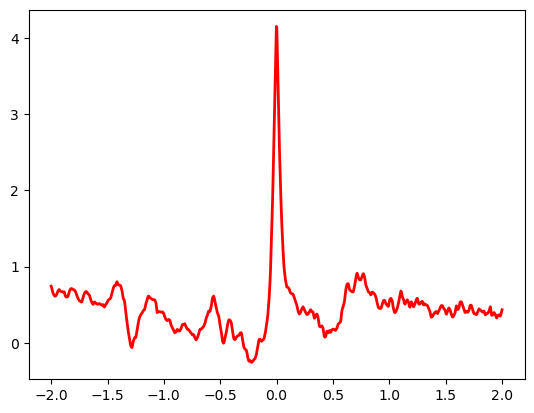

In [63]:
plt.plot(x_common, average_r1, color='red', linewidth=2, label='Average')

shift: 0.508


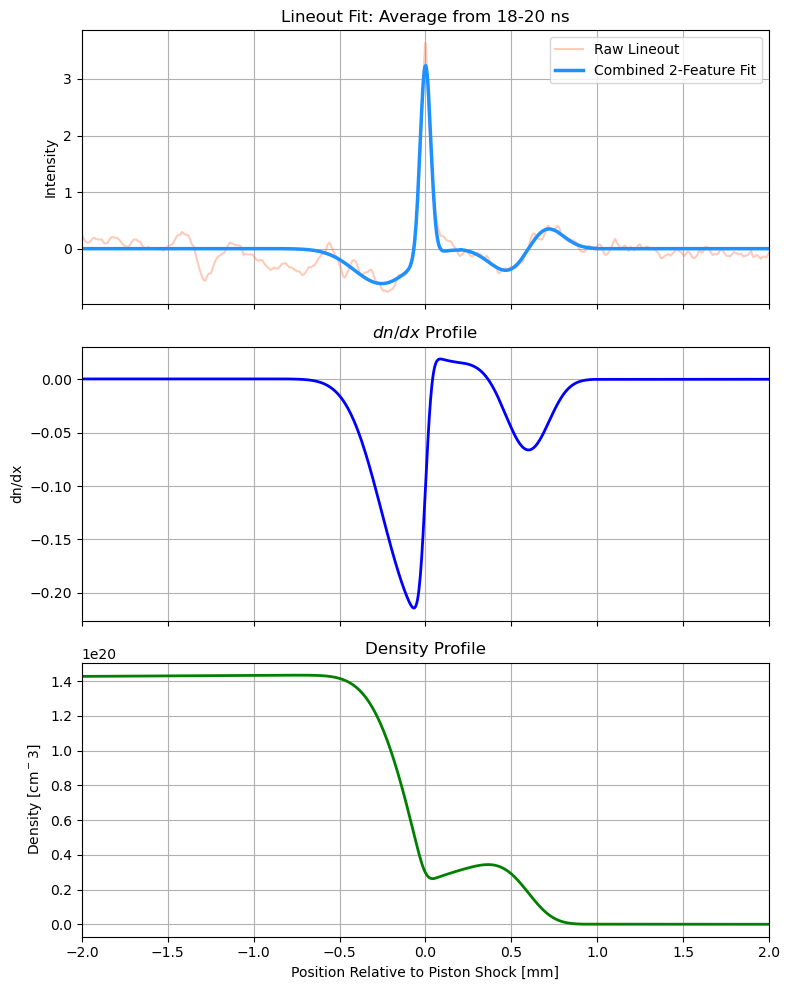

In [64]:
# x = x_common

shift = 0.508
print('shift:', shift)

y_data = average_r1 - shift

# Sort from largest x to smallest x
sort_descending = np.argsort(x_common)[::-1] 

x = x_common[sort_descending]
y_raw = y_data[sort_descending]

# make mask for piston based on min and max positions
mask_piston = (x >= -0.8) & (x <= 0.2)
x_piston, y_piston = x[mask_piston], y_raw[mask_piston]

p0_piston = [
    0, 0.05, -200,  # Negative dip
    -0.3, 0.05,  350   # Positive peak
]

popt_piston, _ = curve_fit(double_gaussian, x_piston, y_piston, p0=p0_piston)

# make mask for magshock based on min and max positions
mask_mag = (x >= 0.1) & (x <= 1)
x_mag, y_mag = x[mask_mag], y_raw[mask_mag]

magshock_min_4 = x_mag[np.argmin(y_mag)]
magshock_max_4 = x_mag[np.argmax(y_mag)]

p0_mag = [
    magshock_min_4, 0.05, -200,  # Negative dip (Note the negative amplitude!)
    magshock_max_4, 0.05,  200   # Positive peak
]

popt_mag, _ = curve_fit(double_gaussian, x_mag, y_mag, p0=p0_mag)

# combine fits and mask to spatial windows - make everywhere else equal to 0
y_fit_piston = np.where(mask_piston, double_gaussian(x, *popt_piston), 0.0)
y_fit_mag    = np.where(mask_mag,    double_gaussian(x, *popt_mag),    0.0)

# get total fit by summing
y_fit_total = y_fit_piston + y_fit_mag

# integrate twice
dn_dx = cumulative_trapezoid(y_fit_total, x, initial=0) 
density = dens_corr * cumulative_trapezoid(dn_dx, x, initial=0)

# plot
fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# top: raw data and fit
axs[0].plot(x, y_raw, color='coral', alpha=0.4, label='Raw Lineout')
axs[0].plot(x, y_fit_total, color='dodgerblue', linewidth=2.5, label='Combined 2-Feature Fit')
axs[0].set_title(f'Lineout Fit: Average from 18-20 ns')
axs[0].set_ylabel('Intensity')
axs[0].set_xlim(-2, 2)
axs[0].legend()
axs[0].grid(True)

# middle: first integration (dn/dx)
axs[1].plot(x, dn_dx, color='blue', linewidth=2)
axs[1].set_title('$dn/dx$ Profile')
axs[1].set_ylabel('dn/dx')
axs[1].grid(True)

# bottom: second integration: density
axs[2].plot(x, density, color='green', linewidth=2)
axs[2].set_title('Density Profile')
axs[2].set_ylabel(f'Density [cm$^{-3}$]')
axs[2].set_xlabel('Position Relative to Piston Shock [mm]')
# axs[2].set_ylim(-5e18, 2e19)
axs[2].grid(True)

plt.tight_layout()
# plt.savefig(f'streak_images/new_dens/t={times_shock_late[i]}_shift={shift:.2f}.jpg')

In [117]:
absmax = []
absmin = []

magshock_max = []
magshock_min = []

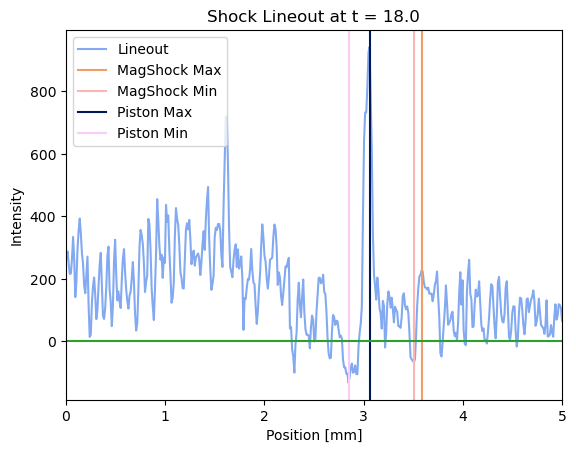

In [13]:
# t = 18
i = 4

plt.plot(pos_shock_late[i], lineouts_shock_bkgdsub_late[i], color = 'cornflowerblue', label = f'Lineout', alpha = 0.8)
x_data = pos_shock_late[i]
y_data = lineouts_shock_bkgdsub_late[i]

mask_piston = (x_data >= 1) & (x_data <= 4)
x_fit_p, y_fit_p = x_data[mask_piston],y_data[mask_piston]
piston_max_4=(x_fit_p[np.argmax(y_fit_p)])
piston_min_4=(x_fit_p[np.argmin(y_fit_p)])

mask_mag = (x_data >= 3.4) & (x_data <= 4)
x_fit, y_fit = x_data[mask_mag],y_data[mask_mag]

magshock_max_4 = x_fit[np.argmax(y_fit)]
magshock_min_4 = x_fit[np.argmin(y_fit)]

plt.axvline(magshock_max_4, color = cm.batlowS(4), label = 'MagShock Max')
plt.axvline(magshock_min_4, color = cm.batlowS(7), label = 'MagShock Min')

plt.axvline(piston_max_4, color = cm.batlowS(0), label = 'Piston Max')
plt.axvline(piston_min_4, color = cm.batlowS(1), label = 'Piston Min')

plt.axhline(0, color = 'tab:green')

# plt.xlim(-1,3)
plt.legend(loc = 'upper left')
plt.xlim(0,5)
plt.title(f'Shock Lineout at t = {times_shock_late[i]}')
plt.xlabel('Position [mm]')
plt.ylabel('Intensity')
plt.show()   

shift: 0


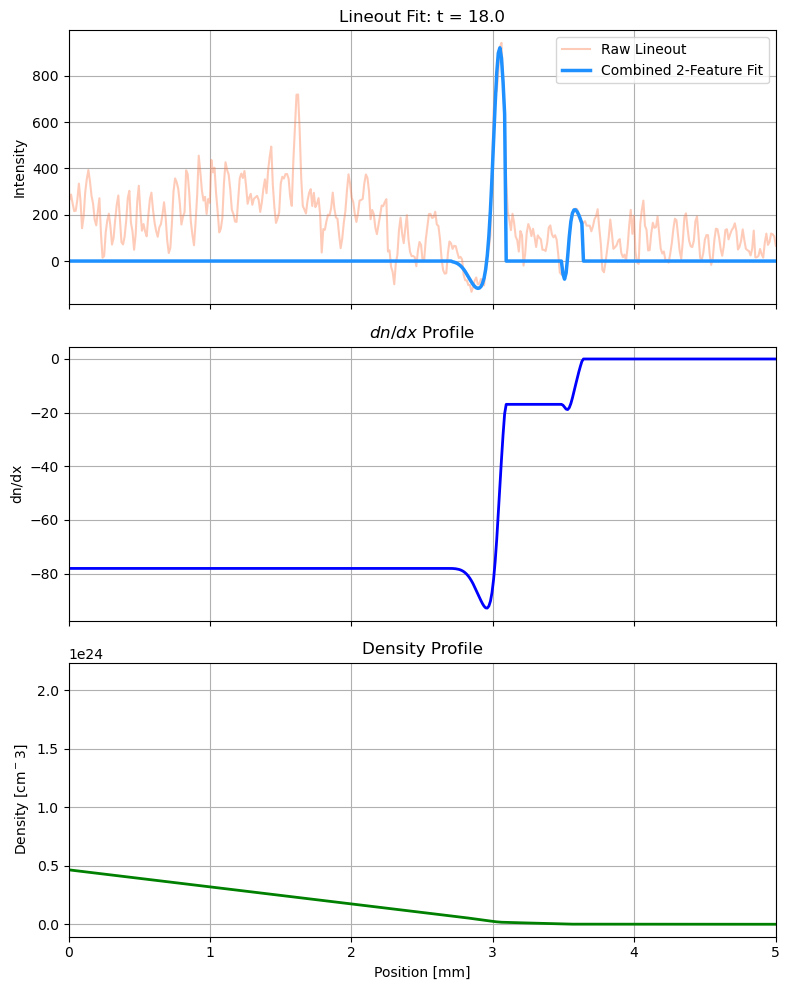

In [14]:
x_data = pos_shock_late[i]
x = x_data

mask_subtract = (x >= -1) & (x <= 0.5)
# mask_subtract_2 = (x > 2.3) & (x < 2.8)
# mask_subtract = mask_subtract_1 | mask_subtract_2
y_data_sub = lineouts_shock_bkgdsub_late[i][mask_subtract]
shift = np.average(y_data_sub)
shift = 0
print('shift:', shift)

y_data = lineouts_shock_bkgdsub_late[i] - shift
y_raw = y_data.copy()

# make mask for piston based on min and max positions
mask_piston = (x >= piston_min_4 - 0.14) & (x <= piston_max_4 + 0.032)
x_piston, y_piston = x[mask_piston], y_raw[mask_piston]

p0_piston = [
    piston_min_4, 0.05, -300,  # Negative dip
    piston_max_4, 0.05,  350   # Positive peak
]

popt_piston, _ = curve_fit(double_gaussian, x_piston, y_piston, p0=p0_piston)

# make mask for magshock based on min and max positions
mask_mag = (x >= magshock_min_4-0.02) & (x <= magshock_max_4+0.05)
x_mag, y_mag = x[mask_mag], y_raw[mask_mag]

magshock_min_4 = x_mag[np.argmin(y_mag)]
magshock_max_4 = x_mag[np.argmax(y_mag)]

p0_mag = [
    magshock_min_4, 0.05, -200,  # Negative dip (Note the negative amplitude!)
    magshock_max_4, 0.05,  200   # Positive peak
]

popt_mag, _ = curve_fit(double_gaussian, x_mag, y_mag, p0=p0_mag)

# combine fits and mask to spatial windows - make everywhere else equal to 0
y_fit_piston = np.where(mask_piston, double_gaussian(x, *popt_piston), 0.0)
y_fit_mag    = np.where(mask_mag,    double_gaussian(x, *popt_mag),    0.0)

# get total fit by summing
y_fit_total = y_fit_piston + y_fit_mag

# integrate twice
dn_dx = cumulative_trapezoid(y_fit_total, x, initial=0) 
density = dens_corr * cumulative_trapezoid(dn_dx, x, initial=0)

# plot
fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# top: raw data and fit
axs[0].plot(x, y_raw, color='coral', alpha=0.4, label='Raw Lineout')
axs[0].plot(x, y_fit_total, color='dodgerblue', linewidth=2.5, label='Combined 2-Feature Fit')
axs[0].set_title(f'Lineout Fit: t = {times_shock_late[i]}')
axs[0].set_ylabel('Intensity')
axs[0].set_xlim(0, 5)
axs[0].legend()
axs[0].grid(True)

# middle: first integration (dn/dx)
axs[1].plot(x, dn_dx, color='blue', linewidth=2)
axs[1].set_title('$dn/dx$ Profile')
axs[1].set_ylabel('dn/dx')
axs[1].grid(True)

# bottom: second integration: density
axs[2].plot(x, density, color='green', linewidth=2)
axs[2].set_title('Density Profile')
axs[2].set_ylabel(f'Density [cm$^{-3}$]')
axs[2].set_xlabel('Position [mm]')
# axs[2].set_ylim(-5e18, 2e19)
axs[2].grid(True)

plt.tight_layout()
plt.savefig(f'streak_images/new_dens/t={times_shock_late[i]}_shift={shift:.2f}.jpg')

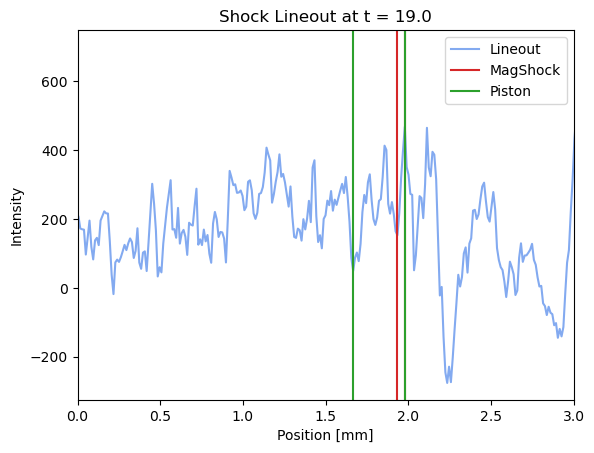

In [15]:
start_index, end_index = 1.75, 2.0

# t = 16
i = 6
plt.plot(pos_shock_late[i], lineouts_shock_bkgdsub_late[i], color = 'cornflowerblue', label = f'Lineout', alpha = 0.8)
x_data = pos_shock_late[i]
y_data = lineouts_shock_bkgdsub_late[i] - 200

mask_piston = (x_data >= 1.45) & (x_data <= 2)
x_fit_p, y_fit_p = x_data[mask_piston],y_data[mask_piston]
piston_max_6=(x_fit_p[np.argmax(y_fit_p)])
piston_min_6=(x_fit_p[np.argmin(y_fit_p)])

mask_mag = (x_data >= start_index) & (x_data <= end_index)
x_fit, y_fit = x_data[mask_mag],y_data[mask_mag]

magshock_max_6 = x_fit[np.argmax(y_fit)]
magshock_min_6 = x_fit[np.argmin(y_fit)]

plt.axvline(magshock_max_6, color = 'tab:red', label = 'MagShock')
plt.axvline(magshock_min_6, color = 'tab:red')

plt.axvline(piston_max_6, color = 'tab:green', label = 'Piston')
plt.axvline(piston_min_6, color = 'tab:green')

plt.xlim(0,3)
plt.title(f'Shock Lineout at t = {times_shock_late[i]}')
plt.xlabel('Position [mm]')
plt.ylabel('Intensity')
plt.legend()
plt.show()   

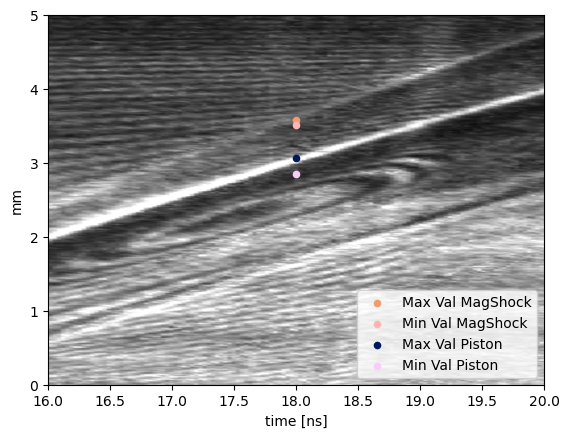

In [16]:
plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.scatter(times_shock_late[4], magshock_max_4, color = cm.batlowS(4), s = 20, label = 'Max Val MagShock')
plt.scatter(times_shock_late[4], magshock_min_4, color = cm.batlowS(7), s = 20, label = 'Min Val MagShock')

plt.scatter(times_shock_late[4], piston_max_4, color = cm.batlowS(0), s = 20, label = 'Max Val Piston')
plt.scatter(times_shock_late[4], piston_min_4, color = cm.batlowS(1), s = 20, label = 'Min Val Piston')

# plt.scatter(times_shock_late[6], magshock_max_6, color = cm.batlowS(4), s = 5, label = 'Max Val MagShock')
# plt.scatter(times_shock_late[6], magshock_min_6, color = cm.batlowS(7), s = 5, label = 'Min Val MagShock')

# plt.scatter(times_shock_late[6], piston_max_6, color = cm.batlowS(0), s = 5, label = 'Max Val Piston')
# plt.scatter(times_shock_late[6], piston_min_6, color = cm.batlowS(1), s = 5, label = 'Min Val Piston')
# plt.scatter(times_shock_late[i], 1.578, color = 'tab:green', s = 5, label = 'Min')

# plt.scatter(times_shock[4], top_line, color = 'tab:red', s = 5, label = 'Local Max')

plt.xlim(16, 20)
plt.ylim(0, 5)
plt.legend(loc = 'lower right')

# plt.savefig('streak_images/bkgd/lineout_positions_shock_late', bbox_inches = 'tight')

In [17]:
# --- 1. Load Data ---

mask_subtract = (x >= -0.5) & (x <= 0.5)
y_data_sub = lineouts_shock_bkgdsub_late[i][mask_subtract]
shift = np.average(y_data_sub)
print(shift)

i = 6
x_data = pos_shock_late[i]
y_data = lineouts_shock_bkgdsub_late[i] - shift

x = x_data
y_raw = y_data.copy()

# Base 2-Gaussian shock model (6 parameters max!)
def double_gaussian(x, x1, w1, A1, x2, w2, A2):
    peak_neg = A1 * np.exp(-((x - x1) / w1)**2)
    peak_pos = A2 * np.exp(-((x - x2) / w2)**2)
    return peak_neg + peak_pos

mask_piston = (x >= piston_min_6 - 0.06) & (x <= piston_max_6 + 0.04)

p0_piston = [
    piston_min_6, 0.1, -300,  # Negative dip
    piston_max_6, 0.1,  350   # Positive peak
]

x_piston, y_piston = x[mask_piston], y_raw[mask_piston]
popt_piston, _ = curve_fit(double_gaussian, x_piston, y_piston, p0=p0_piston)

mask_mag = (x >= magshock_min_6-.04) & (x <= magshock_max_6+.1)

p0_mag = [
    magshock_min_6, 0.1, -200,  # Negative dip (Note the negative amplitude!)
    magshock_max_6, 0.1,  200   # Positive peak
]
x_mag, y_mag = x[mask_mag], y_raw[mask_mag]
popt_mag, _ = curve_fit(double_gaussian, x_mag, y_mag, p0=p0_mag)

# --- 4. Combine Fits into a Single Idealized Array ---
# Calculate each fit across the ENTIRE x-axis, but mask them to their spatial windows
y_fit_piston = np.where(mask_piston, double_gaussian(x, *popt_piston), 0.0)
y_fit_mag    = np.where(mask_mag,    double_gaussian(x, *popt_mag),    0.0)

# Total idealized signal is simply the sum of both clean features!
y_fit_total = y_fit_piston + y_fit_mag

# --- 5. Clean Integration ---
dn_dx = cumulative_trapezoid(y_fit_total, x, initial=0) 
density = cumulative_trapezoid(dn_dx, x, initial=0)

# --- 6. Plotting ---
fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# Top plot: Raw Data + Combined Fit
axs[0].plot(x, y_raw, color='coral', alpha=0.4, label='Raw Lineout')
axs[0].plot(x, y_fit_total, color='dodgerblue', linewidth=2.5, label='Combined 2-Feature Fit')
axs[0].set_title(f'Lineout & Fit (shifted): t = {times_shock_late[i]}')
axs[0].set_ylabel('Intensity')
axs[0].set_xlim(0, 3)
axs[0].legend()
axs[0].grid(True)
axs[0].axvline(magshock_max_6, color = 'tab:red', label = 'MagShock')
axs[0].axvline(magshock_min_6, color = 'tab:red')
axs[0].axvline(piston_max_6, color = 'tab:green', label = 'Piston')
axs[0].axvline(piston_min_6, color = 'tab:green')

# Middle plot: dn/dx
axs[1].plot(x, dn_dx, color='blue', linewidth=2)
axs[1].set_title('$dn/dx$ Profile')
axs[1].set_ylabel('dn/dx')
axs[1].grid(True)

# Bottom plot: Density
axs[2].plot(x, density, color='green', linewidth=2)
axs[2].set_title('Relative Density Profile')
axs[2].set_ylabel('Relative Density')
axs[2].set_xlabel('Position [mm]')
axs[2].grid(True)
plt.ylim(-5,5)

plt.tight_layout()
plt.show()

142.57914230019492


RuntimeError: Optimal parameters not found: Number of calls to function has reached maxfev = 1400.

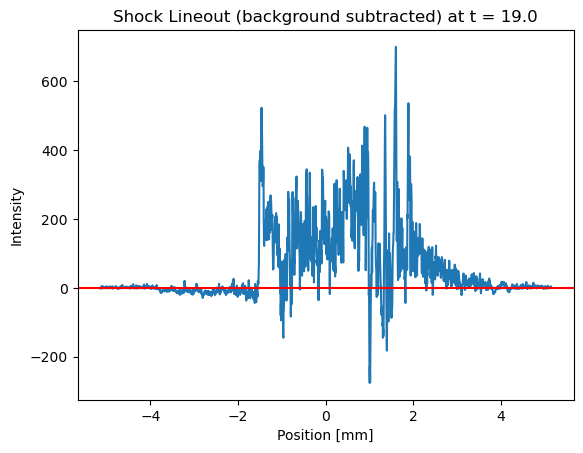

In [27]:
plt.plot(pos_shock_late[i] , lineouts_shock_bkgdsub_late[i])
# plt.xlim(0,3)

plt.axhline(0, color = 'red')

plt.title(f'Shock Lineout (background subtracted) at t = {times_shock_late[i]}')
plt.xlabel('Position [mm]')
plt.ylabel('Intensity')
plt.show()   

In [28]:
# try with not background subbed data

mask_subtract = (x >= 0) & (x <= 0.5)
y_data_sub = lineouts_shock_late[i][mask_subtract]
shift = np.average(y_data_sub)
print(shift)
shift = 100

i = 4
x_data = pos_shock_late[i]
y_data = lineouts_shock_late[i] - shift

x = x_data
y_raw = y_data.copy()

# Base 2-Gaussian shock model (6 parameters max!)
def double_gaussian(x, x1, w1, A1, x2, w2, A2):
    peak_neg = A1 * np.exp(-((x - x1) / w1)**2)
    peak_pos = A2 * np.exp(-((x - x2) / w2)**2)
    return peak_neg + peak_pos

# --- 2. Feature 1: Piston Shock Fit ---
# Define spatial bounds around the piston feature
piston_min_4 = x_data[np.argmin(y_data)]
piston_max_4 = x_data[np.argmax(y_data)]

mask_piston = (x >= piston_min_4 - 0.15) & (x <= piston_max_4 + 0.05)
x_piston, y_piston = x[mask_piston], y_raw[mask_piston]

p0_piston = [
    piston_min_4, 0.05, -300,  # Negative dip
    piston_max_4, 0.05,  350   # Positive peak
]

popt_piston, _ = curve_fit(double_gaussian, x_piston, y_piston, p0=p0_piston)

# --- 3. Feature 2: Magnetic Shock Fit ---
# Define spatial bounds around the second feature (e.g., 1.5 to 1.8 mm)
mask_mag = (x >= 1.56) & (x <= 1.65)
x_mag, y_mag = x[mask_mag], y_raw[mask_mag]

magshock_min_4 = x_mag[np.argmin(y_mag)]
magshock_max_4 = x_mag[np.argmax(y_mag)]

p0_mag = [
    magshock_min_4, 0.05, -200,  # Negative dip (Note the negative amplitude!)
    magshock_max_4, 0.05,  200   # Positive peak
]

popt_mag, _ = curve_fit(double_gaussian, x_mag, y_mag, p0=p0_mag)

# --- 4. Combine Fits into a Single Idealized Array ---
# Calculate each fit across the ENTIRE x-axis, but mask them to their spatial windows
y_fit_piston = np.where(mask_piston, double_gaussian(x, *popt_piston), 0.0)
y_fit_mag    = np.where(mask_mag,    double_gaussian(x, *popt_mag),    0.0)

# Total idealized signal is simply the sum of both clean features!
y_fit_total = y_fit_piston + y_fit_mag

# --- 5. Clean Integration ---
dn_dx = cumulative_trapezoid(y_fit_total, x, initial=0) 
density = cumulative_trapezoid(dn_dx, x, initial=0)

# --- 6. Plotting ---
fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# Top plot: Raw Data + Combined Fit
axs[0].plot(x, y_raw, color='coral', alpha=0.4, label='Raw Lineout')
axs[0].plot(x, y_fit_total, color='dodgerblue', linewidth=2.5, label='Combined 2-Feature Fit')
axs[0].set_title(f'Lineout & Two-Feature Fit: t = {times_shock_late[i]}')
axs[0].set_ylabel('Intensity')
axs[0].set_xlim(0, 3)
axs[0].legend()
axs[0].grid(True)

# Middle plot: dn/dx
axs[1].plot(x, dn_dx, color='blue', linewidth=2)
axs[1].set_title('$dn/dx$ Profile')
axs[1].set_ylabel('dn/dx')
axs[1].grid(True)

# Bottom plot: Density
axs[2].plot(x, density, color='green', linewidth=2)
axs[2].set_title('Relative Density Profile')
axs[2].set_ylabel('Relative Density')
axs[2].set_xlabel('Position [mm]')
axs[2].grid(True)
plt.ylim(-5,5)

plt.tight_layout()
plt.show()

618.5993265993267


ValueError: `ydata` must not be empty!

In [ ]:
magshock_max.append(max_4)
magshock_min.append(min_4)

In [ ]:
plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.scatter(times_shock_late[i], magshock_max, color = 'tab:blue', s = 5, label = 'Max')
plt.scatter(times_shock_late[i], magshock_min, color = 'tab:green', s = 5, label = 'Min')
# plt.scatter(times_shock_late[i], 1.578, color = 'tab:green', s = 5, label = 'Min')

# plt.scatter(times_shock[4], top_line, color = 'tab:red', s = 5, label = 'Local Max')

plt.xlim(10, 30)
plt.legend()

# plt.savefig('streak_images/bkgd/lineout_positions_shock_late', bbox_inches = 'tight')